# Written text as operational data

Written text is one type of data

### Why people write?

 - To communicate: their thoughts, feelings, urgency, needs, information

### Why people communicate?

1. To express emotions
1. To share information
1. To enable or elicit an action
1. ...

### We will use written text for the purpose other than 
1. To experience emotion
1. To learn something the author intended us to learn
1. To do what the author intended us to do

### Instead, we will use written text to recognize who wrote it
 - By calculating and comparing word frequencies in written documents
 
See, for example, likely fictional story https://medium.com/@amuse/how-the-nsa-caught-satoshi-nakamoto-868affcef595

### Example 1. Dictionaries in python (associative arrays)

Plot the frequency distribution of words on a web page.

In [1]:
import requests, re
# re is a module for regular expressions: to detect various combinations of characters
import operator

# Start from a simple document
r = requests .get('http://eecs.utk.edu')

# What comes back includes headers and other HTTP stuff, get just the body of the response
t = r.text

# obtain words by splitting a string using as separator one or more (+) space/like characters (\s) 
wds = re.split('\s+',t)

# now populate a dictionary (wf)
wf = {}
for w in wds:
    if w in wf: wf [w] = wf [w] + 1
    else:  wf[w] = 1

# dictionaries can not be sorted, so lets get a sorted *list*        
wfs = sorted (wf .items(), key = operator .itemgetter (1), reverse=True)   

# lets just have no more than 15 words 
ml = min(len(wfs),15)
for i in range(1,ml,1):
    print (wfs[i][0]+"\t"+str(wfs[i][1]))  

class="menu-item	63
menu-item-type-post_type	61
menu-item-object-page	61
<div	47
</div>	44
and	36
<a	29
-->	26
/>	26
of	25
<link	19
<!--	18
0	18
H.	17


### Example 2

Lots of markup in the output, lets remove it --- 

use BeautifulSoup and nltk modules and practice some regular expressions.

In [2]:
import requests, re, nltk
from bs4 import BeautifulSoup
from nltk import clean_html
from collections import Counter
import operator

# we may not care about the usage of stop words
stop_words = nltk.corpus.stopwords.words('english') + [
 'ut', '\'re','.', ',', '--', '\'s', '?', ')', '(', ':', '\'',
 '\"', '-', '}', '{', '&', '|', u'\u2014' ]

# We most likely would like to remove html markup
def cleanHtml (html):
    from bs4 import BeautifulSoup
    soup = BeautifulSoup(html, 'html.parser')
    return soup .get_text()

# We also want to remove special characters, quotes, etc. from each word
def cleanWord (w):
    # r in r'[.,"\']' tells to treat \ as a regular character 
    # but we need to escape ' with \'
    # any character between the brackets [] is to be removed 
    wn = re.sub('[,"\.\'&\|:@>*;/=]', "", w)
    # get rid of numbers
    return re.sub('^[0-9\.]*$', "", wn)
       
# define a function to get text/clean/calculate frequency
def get_wf (URL):
    # first get the web page
    r = requests .get(URL)
    
    # Now clean
    # remove html markup
    t = cleanHtml (r .text) .lower()
    
    # split string into an array of words using any sequence of spaces "\s+" 
    wds = re .split('\s+',t)
    
    # remove periods, commas, etc stuck to the edges of words
    for i in range(len(wds)):
        wds [i] = cleanWord (wds [i])
    
    # If satisfied with results, lets go to the next step: calculate frequencies
    # We can write a loop to create a dictionary, but 
    # there is a special function for everything in python
    # in particular for counting frequencies (like function table() in R)
    wf = Counter (wds)
    
    # Remove stop words from the dictionary wf
    for k in stop_words:
        wf. pop(k, None)
        
    #how many regular words in the document?
    tw = 0
    for w in wf:
       tw += wf[w] 
        
    
    # Get ordered list
    wfs = sorted (wf .items(), key = operator.itemgetter(1), reverse=True)
    ml = min(len(wfs),15)

    #Reverse the list because barh plots items from the bottom
    return (wfs [ 0:ml ] [::-1], tw)
        
# Now populate two lists    
(wf_ee, tw_ee) = get_wf('http://www.gutenberg.org/ebooks/1342.txt.utf-8')
(wf_bu, tw_bu) = get_wf('http://www.gutenberg.org/ebooks/76.txt.utf-8')

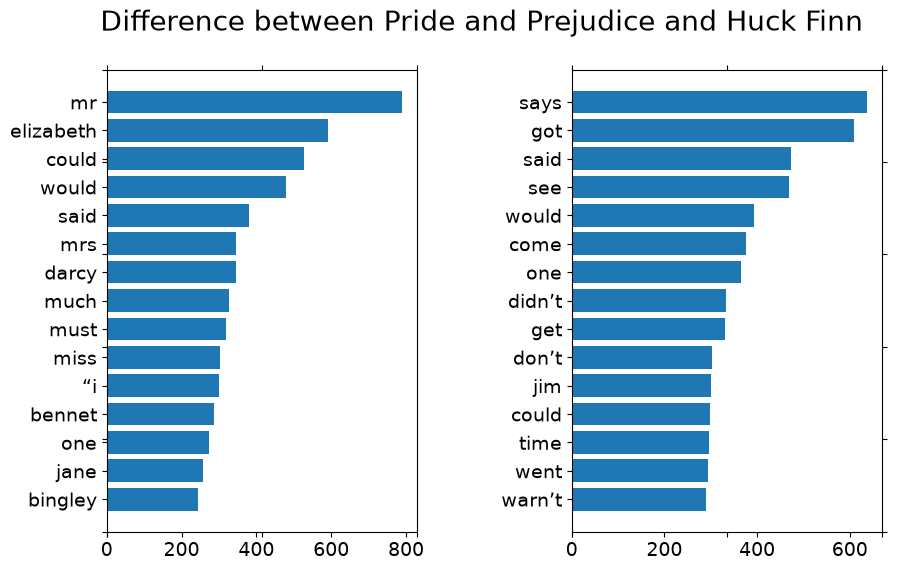

In [3]:
#Plot the results: are there striking differences in language?
import numpy as np
import pylab
import matplotlib.pyplot as plt

%matplotlib inline
def plotTwoLists (wf_ee, wf_bu, title):
    f = plt.figure (figsize=(10, 6))
    # this is painfully tedious....
    f .suptitle (title, fontsize=20)
    ax = f.add_subplot(111)
    ax .spines ['top'] .set_color ('none')
    ax .spines ['bottom'] .set_color ('none')
    ax .spines ['left'] .set_color ('none')
    ax .spines ['right'] .set_color ('none')
    ax .tick_params (labelcolor='w', top='off', bottom='off', left='off', right='off', labelsize=20)

    # Create two subplots, this is the first one
    ax1 = f .add_subplot (121)
    plt .subplots_adjust (wspace=.5)

    pos = np .arange (len(wf_ee)) 
    ax1 .tick_params (axis='both', which='major', labelsize=14)
    pylab .yticks (pos, [ x [0] for x in wf_ee ])
    ax1 .barh (range(len(wf_ee)), [ x [1] for x in wf_ee ], align='center')

    ax2 = f .add_subplot (122)
    ax2 .tick_params (axis='both', which='major', labelsize=14)
    pos = np .arange (len(wf_bu)) 
    pylab .yticks (pos, [ x [0] for x in wf_bu ])
    ax2 .barh (range (len(wf_bu)), [ x [1] for x in wf_bu ], align='center')

plotTwoLists (wf_ee, wf_bu, 'Difference between Pride and Prejudice and Huck Finn')

In [4]:
#In case Project gutenberg is blocked you can download text to your laptop and copy to the docker container via scp
#Assuming the file name you copy is pg4680.txt here is how you change the script
# Please note the option errors='replace'
# without it python invariably runs into unicode errors
f = open ('pg4680.txt', 'r', encoding="ascii", errors='replace')
    
# What comes back includes headers and other HTTP stuff, get just the body of the response
t = f.read()

# obtain words by splitting a string using as separator one or more (+) space/like characters (\s) 
wds = re.split('\s+',t)

# now populate a dictionary (wf)
wf = {}
for w in wds:
    if w in wf: wf [w] = wf [w] + 1
    else:  wf [w] = 1

# dictionaries can not be sorted, so lets get a sorted *list*        
wfs = sorted (wf .items(), key = operator .itemgetter (1), reverse=True)   

# lets just have no more than 15 words 
ml = min(len(wfs),15)
for i in range(1,ml,1):
    print (wfs[i][0]+"\t"+str(wfs[i][1]))  

and	2836
of	2676
to	2646
a	2217
in	1422
his	1205
he	928
that	920
was	823
for	798
with	797
as	672
I	505
you	497


# Assignment 1

1. Compare word frequencies between two works of a single author.
1. Compare word frequencies between works of two authors.
1. Are there some words preferred by one author but used less frequently by another author?

Extra credit

1. The frequency of a specific word, e.g., "would" should follow a binomial distribution (each regular word in a document is a trial and with probability p that word is "would". The estimate for p is N("would")/N(regular word)). Do these binomial distributions for your chosen word differ significantly between books of the same author or between authors? 

Project Gutenberg is a good source of for fiction and non-fiction.

E.g below are two most popular books from Project Gutenberg:
- Pride and Prejudice at http://www.gutenberg.org/ebooks/1342.txt.utf-8
- Adventures of Huckleberry Finn at http://www.gutenberg.org/ebooks/76.txt.utf-8

## INITIAL DESCRIPTION

DATA:

- Rollo in Scotland by Jacob Abbott: 'https://www.gutenberg.org/ebooks/25174.txt.utf-8',
- Rollo in Switzerland by Jacob Abbott: 'https://www.gutenberg.org/ebooks/22377.txt.utf-8',
- The Young Adventurer; or, Tom's Trip Across the Plains by Jr. Horatio Alger: 'https://www.gutenberg.org/ebooks/27300.txt.utf-8',

GOAL:

First compare the two Jacob Abbott books for their word frequencies, and then compare one of the Jacob Abbott books with the Jr. Horatio Alger's book. This will help us understand how the word choices are for adventure textbooks and how they change with authors and the story.

WAYS TO ACHIEVE THE GOAL:

- To make it even and uniform, I first need to remove the license and other unwanted pages in the book.
- Then, instead of raw word frequency calculation, I need to come up with a logic to get the average representation as it would be unfair if a book has a lot of words in general and the other has less. However, the books I chose that similar total word counts, so this would not be a problem.
- First, I would analyze the two books by Jacob Abbott to see the differences in their word frequencies, and then compare on of them with the other book by Jr. Horatio Alger.

In [5]:
import requests, re, nltk
#In case your text is not on Project Gutenberg but at some other URL
#http://www.fullbooks.com/Our-World-or-The-Slaveholders-Daughter2.html
# that contains 12 parts
t = ""
for i in range(2,13):
  r = requests .get('http://www.fullbooks.com/Our-World-or-The-Slaveholders-Daughter' + str(i) + '.html')
  t = t + r.text

In [6]:
len(t)

1323653

## TASK 1

In [7]:
import requests, re, nltk
from bs4 import BeautifulSoup
from nltk import clean_html
from collections import Counter
import operator

# we may not care about the usage of stop words
stop_words = nltk.corpus.stopwords.words('english') + [
 'ut', '\'re','.', ',', '--', '\'s', '?', ')', '(', ':', '\'',
 '\"', '-', '}', '{', '&', '|', u'\u2014' ]

# We most likely would like to remove html markup
def cleanHtml (html):
    from bs4 import BeautifulSoup
    soup = BeautifulSoup(html, 'html.parser')
    return soup .get_text()

# We also want to remove special characters, quotes, etc. from each word
def cleanWord (w):
    # r in r'[.,"\']' tells to treat \ as a regular character 
    # but we need to escape ' with \'
    # any character between the brackets [] is to be removed 
    wn = re.sub('[,"\.\'&\|:@>*;/=]', "", w)
    # get rid of numbers
    return re.sub('^[0-9\.]*$', "", wn)
       
# define a function to get text/clean/calculate frequency
def get_wf (URL, full=False):
    # first get the web page
    r = requests .get(URL)
    
    # Now clean
    # remove html markup
    t = cleanHtml (r .text) .lower()
    
    # split string into an array of words using any sequence of spaces "\s+" 
    wds = re .split('\s+',t)
    
    # remove periods, commas, etc stuck to the edges of words
    for i in range(len(wds)):
        wds [i] = cleanWord (wds [i])
    
    # If satisfied with results, lets go to the next step: calculate frequencies
    # We can write a loop to create a dictionary, but 
    # there is a special function for everything in python
    # in particular for counting frequencies (like function table() in R)
    wf = Counter (wds)
    
    # Remove stop words from the dictionary wf
    for k in stop_words:
        wf. pop(k, None)
        
    #how many regular words in the document?
    tw = 0
    for w in wf:
       tw += wf[w] 
        
    
    # Get ordered list
    wfs = sorted (wf .items(), key = operator.itemgetter(1), reverse=True)
    ml = min(len(wfs),15)

    if full:
        return (wf, tw)
    wfs = sorted (wf .items(), key = operator.itemgetter(1), reverse=True)
    ml = min(len(wfs),15)
    return (wfs [ 0:ml ] [::-1], tw)

    #Reverse the list because barh plots items from the bottom
    return (wfs [ 0:ml ] [::-1], tw)
        
# Now populate two lists    
(wf_abbottScot, tw_abbottScot) = get_wf('https://www.gutenberg.org/ebooks/25174.txt.utf-8')
(wf_abbottSwiz, tw_abbottSwiz) = get_wf('https://www.gutenberg.org/ebooks/22377.txt.utf-8')
(wf_youngAdvHorAlg, tw_youngAdvHorAlg) = get_wf('https://www.gutenberg.org/ebooks/27300.txt.utf-8')

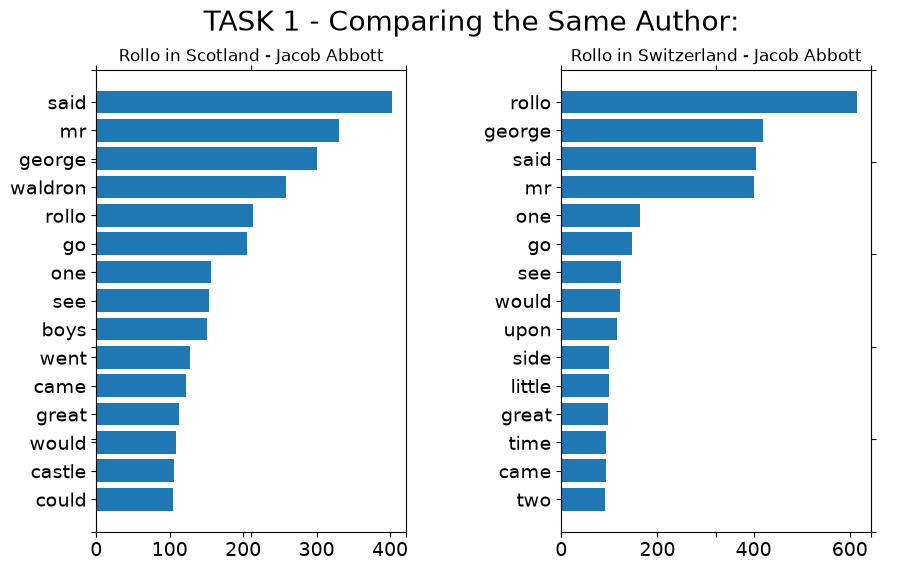

In [8]:
#Plot the results: are there striking differences in language?
import numpy as np
import pylab
import matplotlib.pyplot as plt

%matplotlib inline
def plotTwoLists (wf_abbottScot, wf_abbottSwiz, title, title1, title2):
    f = plt.figure (figsize=(10, 6))
    # this is painfully tedious....
    f .suptitle (title, fontsize=20)
    ax = f.add_subplot(111)
    ax .spines ['top'] .set_color ('none')
    ax .spines ['bottom'] .set_color ('none')
    ax .spines ['left'] .set_color ('none')
    ax .spines ['right'] .set_color ('none')
    ax .tick_params (labelcolor='w', top='off', bottom='off', left='off', right='off', labelsize=20)

    # Create two subplots, this is the first one
    ax1 = f .add_subplot (121)
    ax1.set_title(title1)
    plt .subplots_adjust (wspace=.5)

    pos = np .arange (len(wf_abbottScot)) 
    ax1 .tick_params (axis='both', which='major', labelsize=14)
    pylab .yticks (pos, [ x [0] for x in wf_abbottScot ])
    ax1 .barh (range(len(wf_abbottScot)), [ x [1] for x in wf_abbottScot ], align='center')

    ax2 = f .add_subplot (122)
    ax2.set_title(title2)
    ax2 .tick_params (axis='both', which='major', labelsize=14)
    pos = np .arange (len(wf_abbottSwiz)) 
    pylab .yticks (pos, [ x [0] for x in wf_abbottSwiz ])
    ax2 .barh (range (len(wf_abbottSwiz)), [ x [1] for x in wf_abbottSwiz ], align='center')

plotTwoLists (wf_abbottScot, wf_abbottSwiz, "TASK 1 - Comparing the Same Author:", 'Rollo in Scotland - Jacob Abbott', 'Rollo in Switzerland - Jacob Abbott')

In both works of Jacob Abbott, he seems to use certain character names a lot with Mr. salutation. Also, it seems the books that he writes are based on dialogues as the word said has been really common in both the works.
Being an adventure book, they both seem to have high frequencies of words like "great", "came", and "go".
Rollo in Scotland seems to have a lot of "boys" and "castle" in it, and Rollo in Switzerland seems to have a lot of "little" and "side" in it.

## TASK 2

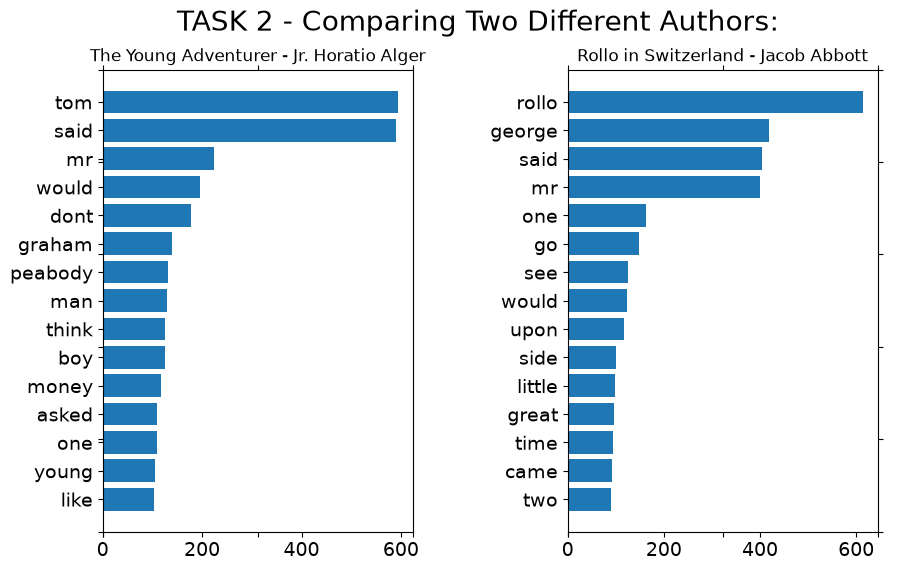

In [9]:


plotTwoLists (wf_youngAdvHorAlg, wf_abbottSwiz, "TASK 2 - Comparing Two Different Authors:", 'The Young Adventurer - Jr. Horatio Alger' , 'Rollo in Switzerland - Jacob Abbott')

Jr. Horatio Alger is similar to Jacob Abbott as he uses a lot of character names, "mr", and "said".
At the same time, there are words like "boy", "man", "money", and "young" being used a lot to represent the adventurous nature of the book and gives us some hints that the story might be related to money and involves men.
Rollo in Switzerland seems to be a story more about the time and greatness involved in a particular point in time.

## TASK 3

In [10]:
(all_abbottSwiz, tot_abbottSwiz) = get_wf('https://www.gutenberg.org/ebooks/22377.txt.utf-8', True)
(all_youngAdvHorAlg, tot_youngAdvHorAlg) = get_wf('https://www.gutenberg.org/ebooks/27300.txt.utf-8', True)

In [11]:
# Getting the most used words by the author
def popularWords (wf, tw, n):
    wfs = sorted (wf.items(), key = operator.itemgetter(1), reverse=True)
    return [ (w, c) for (w, c) in wfs [0:n] ]

In [12]:
# Finding the least used words from the other author
def rareWords (topWords, wf2, tw2):
    results = []
    for (w, c1) in topWords:
        c2 = wf2 .get (w, 0)
        ratio = float('inf') if c2 == 0 else c1 / c2
        results.append ((w, c1, c2, ratio))
    results.sort (key = operator .itemgetter(3), reverse=True)
    return results

def finalResult (results, name1, name2):
    print (f"\n{'Word':<15}{name1:>8}{name2:>8}{'Ratio':>10}")
    for i in range (50):
        print("-", end="")
    print()
    for (w, c1, c2, ratio) in results:
        r = "Never" if c2 == 0 else f"{ratio:.1f}x"
        print (f"{w:<15}{c1:>8}{c2:>8}{r:>10}")

In [13]:
topAbbott = popularWords(all_abbottSwiz, tot_abbottSwiz, 15)
res = rareWords(topAbbott, all_youngAdvHorAlg, tot_youngAdvHorAlg)
finalResult(res, 'Abbott', 'Alger')


Word             Abbott   Alger     Ratio
--------------------------------------------------
rollo               614       0     Never
george              419       0     Never
side                100      11      9.1x
great                97      34      2.9x
little               99      42      2.4x
came                 92      41      2.2x
mr                  400     223      1.8x
go                  148      97      1.5x
see                 125      82      1.5x
one                 163     109      1.5x
upon                116      78      1.5x
two                  90      71      1.3x
time                 94      77      1.2x
said                405     591      0.7x
would               123     195      0.6x


As expected, there are characted names from Abbott's book that are not in Alger's  book. 
In terms of other words, Abbott seems to use "side" a way lot more than Alger. For instance, Abbott used the word "side" around 9 times more than Alger. This gives insight about their stories.

In [14]:
topAlger = popularWords(all_youngAdvHorAlg, tot_youngAdvHorAlg, 15)
res2 = rareWords(topAlger, all_abbottSwiz, tot_abbottSwiz)
finalResult(res2, 'Alger', 'Abbott')


Word              Alger  Abbott     Ratio
--------------------------------------------------
tom                 594       0     Never
graham              139       0     Never
peabody             131       0     Never
money               118      17      6.9x
dont                177      27      6.6x
boy                 125      20      6.2x
young               105      22      4.8x
think               126      30      4.2x
man                 130      31      4.2x
like                104      62      1.7x
asked               109      66      1.7x
would               195     123      1.6x
said                591     405      1.5x
one                 109     163      0.7x
mr                  223     400      0.6x


Words like "money", "dont", "boy", "young", "think", and "man" seem to be extensively used by Alger than Abbott.
Also, it can be noted that there are few words like this that seem to be used more by Alger compared to Abbott than vice versa. 

## EXTRA CREDIT

In [15]:
(all_abbottScot, tot_abbottScot) = get_wf('https://www.gutenberg.org/ebooks/25174.txt.utf-8', True)

In [16]:
from scipy.stats import norm
import math

In [17]:
def test(book1, book2, wordList1, wordList2, countList1, countList2, word='would'):
    print(f"\nWord: '{word}'")
    a = wordList1.get(word, 0)
    b = wordList2.get(word, 0)

    p1 = a/countList1
    p2 = b/countList2
    pool = ((a + b)/(countList1 + countList2))
    z = (p1 - p2)/math.sqrt(pool*(1 - pool)*(1/countList1 + 1/countList2))
    pvalue = 2*(1-norm.cdf(abs(z)))

    print(book1, " p1: ", p1)
    print(book2, " p2: ", p2)
    print("z:", z)
    print("pvalue:", pvalue)
    

In [18]:
test("Rollo in Switzerland - Jacob Abbott", "The Young Adventurer - Jr. Horatio Alger", all_abbottSwiz, all_youngAdvHorAlg, tot_abbottSwiz, tot_youngAdvHorAlg, 'would')


Word: 'would'
Rollo in Switzerland - Jacob Abbott  p1:  0.005468367936691415
The Young Adventurer - Jr. Horatio Alger  p2:  0.008311311908618191
z: -3.6750968534275845
pvalue: 0.00023775920177082632


In [19]:
test("Rollo in Switzerland - Jacob Abbott", "Rollo in Scotland - Jacob Abbott", all_abbottSwiz, all_abbottScot, tot_abbottSwiz, tot_abbottScot, 'would')


Word: 'would'
Rollo in Switzerland - Jacob Abbott  p1:  0.005468367936691415
Rollo in Scotland - Jacob Abbott  p2:  0.0050267478325032285
z: 0.6420097299422878
pvalue: 0.5208668654497535


We can see that the p values for the books with same author are more similar, and also the higher p-value tells us that Jacob Abbott does not differ much between his works.
But a comparatively lower p value for Jacob Abbott and Jr. Horatio Alger tells us that they both have different word choices and different frequencies.
Also, a lower z value in the second case tells us that there is little gap compared to first case.